# Model overdispersed counts

Count data can vary more than a Poisson model allows. We will simulate overdispersed counts, fit Poisson and negative-binomial GAMs with the same mean structure, and compare their residuals and predictions.

## Simulate counts with exposure

We draw negative-binomial responses with variance $\mu+\mu^2/\theta$ and true $\theta=2$. Both models include the same known log-exposure offset with coefficient one.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson, nbinom
from sklearn.model_selection import train_test_split
from nampy.gam import GAM
from nampy.gam.families import NegativeBinomialLogFamily

rng=np.random.default_rng(106)
data=pd.DataFrame({"x":rng.uniform(0,1,900),"exposure":rng.uniform(.5,3,900)})
data["log_exposure"]=np.log(data.exposure)
mu=data.exposure*np.exp(.7+np.sin(2*np.pi*data.x))
data["y"]=rng.negative_binomial(2,2/(2+mu))
train,test=train_test_split(data,test_size=.25,random_state=106)
formula="y ~ s(x,bs='cr',k=12) + offset(log_exposure)"
models={"Poisson":GAM(formula=formula,family="poisson",optimize_smoothing=True,smoothing_method="reml").fit(train),
        "Negative binomial":GAM(formula=formula,family=NegativeBinomialLogFamily(theta=1,estimate_theta=True),optimize_smoothing=True,smoothing_method="reml").fit(train)}
theta=float(np.asarray(models["Negative binomial"].family.getTheta(trans=True)).reshape(-1)[0])
pd.DataFrame({"Parameter":["True theta","Estimated theta"],"Value":[2,theta]}).style.hide(axis="index").format({"Value":"{:.3f}"})

Parameter,Value
True theta,2.000
Estimated theta,2.429


## Inspect fitted means and residuals

The mean curves use exposure one. Pearson residuals use each fitted family's variance, so remaining spread is assessed relative to the model's own variance assumption.

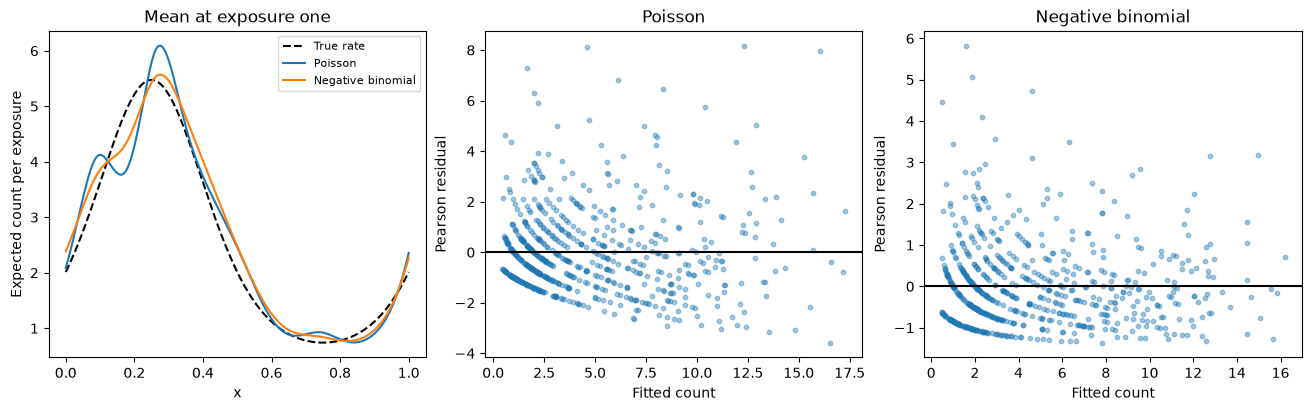

In [2]:
grid=pd.DataFrame({"x":np.linspace(0,1,180),"log_exposure":0.})
figure,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
axes[0].plot(grid.x,np.exp(.7+np.sin(2*np.pi*grid.x)),"k--",label="True rate")
for axis,(name,model) in zip(axes[1:],models.items()):
    axes[0].plot(grid.x,model.predict(grid,type="response"),label=name)
    axis.scatter(model.predict(train,type="response"),model.residuals(type="pearson"),s=10,alpha=.4)
    axis.axhline(0,color="black")
    axis.set(title=name,xlabel="Fitted count",ylabel="Pearson residual")
axes[0].set(xlabel="x",ylabel="Expected count per exposure",title="Mean at exposure one")
axes[0].legend(fontsize=8)
plt.show()
plt.close(figure)

## Compare held-out count predictions

The mean negative log probability uses each fitted discrete probability distribution and is comparable on the same test rows. Larger theta approaches a Poisson variance; smaller theta permits more overdispersion. No prediction interval is inferred from a mean standard error.

In [3]:
rows=[]
for name,model in models.items():
    mean=np.asarray(model.predict(test,type="response"))
    log_probability=poisson.logpmf(test.y,mean) if name=="Poisson" else nbinom.logpmf(test.y,theta,theta/(theta+mean))
    rows.append({"Model":name,"Test mean negative log probability":-log_probability.mean(),"Test mean absolute error":np.mean(np.abs(test.y-mean))})
pd.DataFrame(rows).style.hide(axis="index").format({"Test mean negative log probability":"{:.3f}","Test mean absolute error":"{:.3f}"})

Model,Test mean negative log probability,Test mean absolute error
Poisson,2.662,2.763
Negative binomial,2.207,2.744


The estimated theta is 2.429, compared with the simulation value 2. The negative-binomial fit improves mean test negative log probability from 2.662 to 2.207, while mean absolute errors are similar. This illustrates why a comparable probabilistic score can reveal a variance mismatch that a mean-error measure largely misses.